# 06 – Comparaison des approches : laquelle est la plus utile ?

**Question centrale du projet :** pour éviter les pannes imprévues, vaut-il mieux un **classifieur** (« panne dans 48 h ? »), une **détection d'anomalies**, un **modèle de survie** (âge de remplacement) ou simplement **attendre la panne** ?

Ce notebook **ne réentraîne rien** : il lit les résultats déjà produits par les autres notebooks (`reports/tables/*.csv`) et les met côte à côte.

| Approche | Notebook | Question |
|---|---|---|
| Classification AI4I | `03` | La machine va-t-elle tomber en panne ? (jeu de prise en main) |
| Classification synthétique + SHAP | `03b`, `08` | Panne dans les 48 h ? Pourquoi ? |
| Détection d'anomalies | `04` | La machine se comporte-t-elle anormalement ? |
| Modèles de survie | `05` | Dans combien de temps ? À quel âge remplacer ? |
| Coût | `07`, `09` | Quelle politique coûte le moins cher (MAD) ? |

⚠️ Données **synthétiques** (dégradation simulée, lisse) et coûts **illustratifs** : les scores sont élevés et les gains sont une **démonstration de méthode**, pas un chiffrage pour une vraie usine.

## 1. Chargement des résultats

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "features.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from features import SENSOR_COLS
T, F = ROOT / "reports/tables", ROOT / "reports/figures"
F.mkdir(parents=True, exist_ok=True)

def charger(nom, **kw):
    p = T / nom
    if not p.exists():
        raise FileNotFoundError(f"{nom} introuvable : lance d'abord le notebook qui le produit (voir le tableau en haut).")
    return pd.read_csv(p, **kw)

class_ai4i  = charger("resultats_classification.csv", index_col=0)
class_synth = charger("resultats_classification_synthetique.csv", index_col=0)
anomalies   = charger("resultats_anomalies.csv", index_col=0)
survie      = charger("resultats_survie.csv", index_col=0)
cout        = charger("resultats_cout_classifieur.csv", index_col=0)   # contient aussi les politiques de 07
sensib      = charger("resultats_cout_sensibilite.csv", index_col=0)
shap_imp    = charger("shap_importance.csv", index_col=0).iloc[:, 0]
print("6 tableaux chargés")

6 tableaux chargés


## 2. Classification (supervisée)

Le classifieur apprend à partir d'exemples étiquetés « panne / pas panne ». Deux jeux de données : **AI4I** (lignes indépendantes, 3,4 % de pannes) et les **données synthétiques** (historiques par machine, « panne dans 48 h », 1,7 % de pannes, découpage **par machine**).

In [2]:
display(class_ai4i.round(3).rename_axis("AI4I (03)"))
display(class_synth.round(3).rename_axis("Synthétique (03b)"))

,PR-AUC,ROC-AUC,Recall,Précision,F1
AI4I (03),,,,,
Régression logistique,0.403,0.932,0.838,0.170,0.283
Random Forest,0.899,0.987,0.838,0.983,0.905
XGBoost,0.861,0.989,0.853,0.716,0.779


,PR-AUC (CV train),PR-AUC (test),ROC-AUC (test),Recall,Précision,F1
Synthétique (03b),,,,,,
Régression logistique,0.868,0.834,0.997,0.980,0.453,0.619
Random Forest,0.850,0.883,0.998,0.920,0.695,0.792
XGBoost,0.866,0.892,0.998,0.966,0.633,0.765


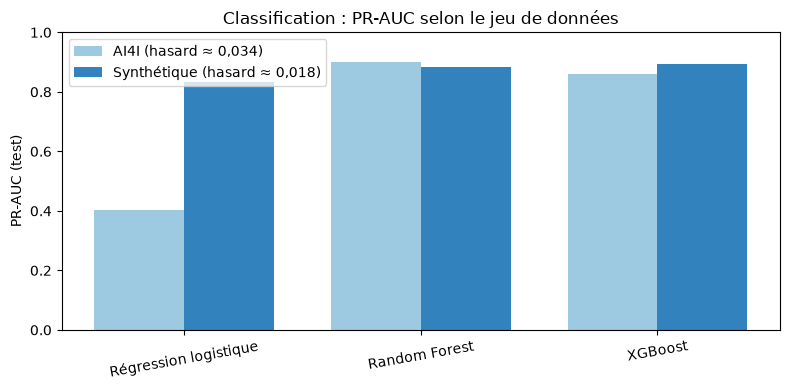

In [3]:
modeles = class_synth.index
x = np.arange(len(modeles)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w/2, class_ai4i.loc[modeles, "PR-AUC"], w, label="AI4I (hasard ≈ 0,034)", color="#9ecae1")
ax.bar(x + w/2, class_synth.loc[modeles, "PR-AUC (test)"], w, label="Synthétique (hasard ≈ 0,018)", color="#3182bd")
ax.set_xticks(x); ax.set_xticklabels(modeles, rotation=10); ax.set_ylabel("PR-AUC (test)"); ax.set_ylim(0, 1)
ax.set_title("Classification : PR-AUC selon le jeu de données"); ax.legend()
plt.tight_layout(); plt.savefig(F / "comparaison_classification.png", dpi=150); plt.show()

## 3. Détection d'anomalies (non supervisée)

Pas besoin d'étiquettes « panne » : les modèles apprennent le comportement **sain** et signalent ce qui s'en écarte.

In [4]:
anomalies.round(3)

,ROC-AUC,PR-AUC,seuil,pannes détectées,taux de détection,délai médian (h),fausses alarmes (sain)
modèle,,,,,,,
Isolation Forest,0.941,0.314,0.522,43/44,0.977,1038.0,0.009
One-Class SVM,0.983,0.576,-1.796,43/44,0.977,667.0,0.002
Autoencodeur,0.955,0.391,2.200,43/44,0.977,592.0,0.000


## 4. Survie : à quel âge remplacer ?

Le modèle de survie (Weibull) estime la durée de vie des machines et donne l'**âge de remplacement** `T*` qui minimise le coût.

In [5]:
survie[["forme ρ estimée", "âge optimal de remplacement T* (h)", "économie"]]

,forme ρ estimée,âge optimal de remplacement T* (h),économie
type,,,
broyeur,1.77,860,33%
compresseur,2.36,1330,49%
ventilateur,2.33,1210,49%


## 5. Comparaison **sur le même critère** : détecter « panne dans 48 h »

Le classifieur (`03b`) et les anomalies (`04`) sont évalués sur la **même cible** (`failure_within_h`) et les **mêmes machines de test**, donc leur **PR-AUC** est directement comparable. Un modèle au hasard a une PR-AUC ≈ 0,018.

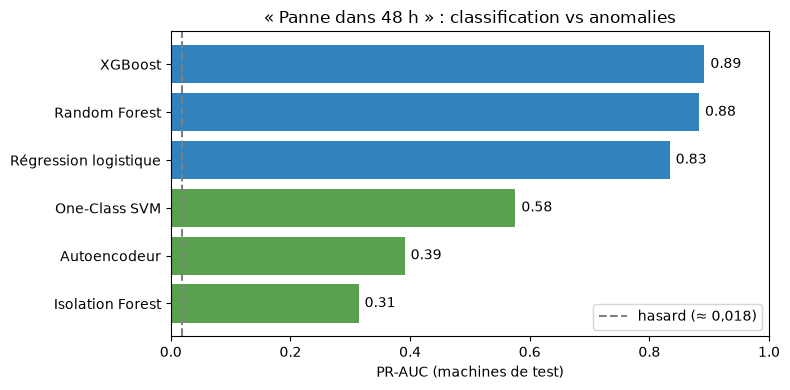

In [6]:
comp = pd.concat([
    class_synth["PR-AUC (test)"].rename("PR-AUC").to_frame().assign(famille="Classification (supervisée)"),
    anomalies["PR-AUC"].to_frame().assign(famille="Anomalies (non supervisée)"),
]).sort_values("PR-AUC")

fig, ax = plt.subplots(figsize=(8, 4))
couleur = comp.famille.map({"Classification (supervisée)": "#3182bd", "Anomalies (non supervisée)": "#59a14f"})
ax.barh(comp.index, comp["PR-AUC"], color=couleur)
ax.axvline(0.018, color="gray", ls="--", label="hasard (≈ 0,018)"); ax.legend(loc="lower right")
ax.set_xlabel("PR-AUC (machines de test)"); ax.set_xlim(0, 1)
ax.set_title("« Panne dans 48 h » : classification vs anomalies")
for i, v in enumerate(comp["PR-AUC"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
plt.tight_layout(); plt.savefig(F / "comparaison_pr_auc.png", dpi=150); plt.show()

## 6. Le critère qui compte pour l'entreprise : le **coût** (MAD)

Chaque politique est évaluée sur les mêmes machines de test avec les mêmes hypothèses de coût (`07` et `09`) : coût moyen en MAD par heure de fonctionnement.

In [7]:
cout

,MAD/h,MAD/an/machine,économie vs corrective
Corrective (attendre la panne),457.099758,3657000.0,0%
Préventive à âge fixe,297.864568,2383000.0,35%
Prédictive (alarme anomalies),106.280236,850000.0,77%
"Prédictive (classifieur, seuil 0,5)",79.404910,635000.0,83%
"Prédictive (classifieur, seuil coût = 0.8)",79.154404,633000.0,83%
Idéale (limite théorique),77.890082,623000.0,83%


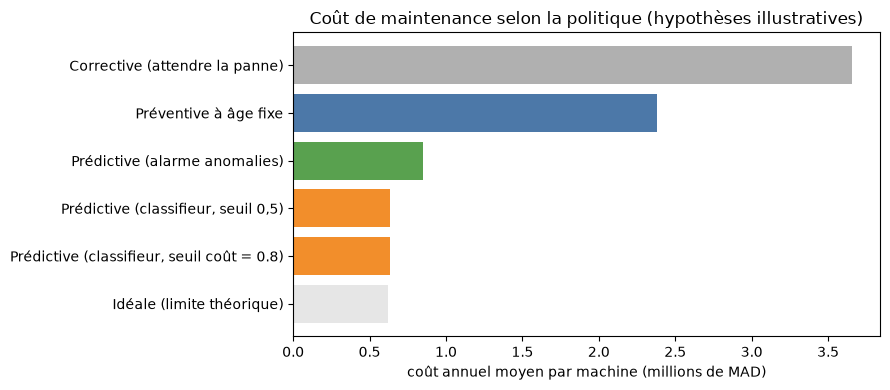

In [8]:
c = cout["MAD/h"].sort_values(ascending=False)
def couleur_politique(nom):
    if nom.startswith("Corrective"): return "#b0b0b0"
    if nom.startswith("Préventive"): return "#4c78a8"
    if "anomalies" in nom: return "#59a14f"
    if "classifieur" in nom: return "#f28e2b"
    return "#e6e6e6"
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(list(c.index)[::-1], (c * 8000 / 1e6).values[::-1], color=[couleur_politique(n) for n in c.index][::-1])
ax.set_xlabel("coût annuel moyen par machine (millions de MAD)")
ax.set_title("Coût de maintenance selon la politique (hypothèses illustratives)")
plt.tight_layout(); plt.savefig(F / "comparaison_cout.png", dpi=150); plt.show()

### Et si les coûts sont faux ?

Le classement résiste-t-il quand la perte de production par heure d'arrêt est multipliée par un facteur ? (analyse de `07` : corrective, âge fixe, alarme par anomalies, idéale.)

In [9]:
(sensib * 8000 / 1e6).round(2).rename_axis("facteur perte prod").rename(columns=lambda c: c + " (M MAD/an)")

,corrective (M MAD/an),fixe (M MAD/an),alarme (M MAD/an),idéale (M MAD/an)
facteur perte prod,,,,
0.10,0.67,0.43,0.14,0.10
0.25,1.17,0.78,0.26,0.19
0.50,2.00,1.32,0.46,0.33
1.00,3.66,2.38,0.85,0.62
2.00,6.98,4.53,1.64,1.20
4.00,13.62,8.83,3.21,2.36


## 7. Pourquoi le classifieur alerte ? (SHAP)

Importance moyenne de chaque variable dans les décisions de XGBoost (`08_shap`), regroupée par capteur et par type de feature.

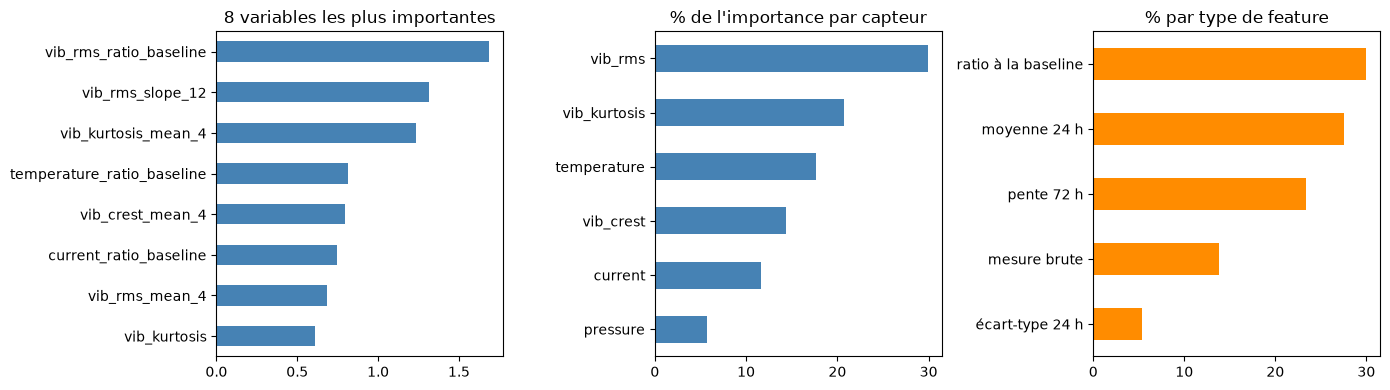

In [10]:
def capteur(f): return next(s for s in SENSOR_COLS if f.startswith(s))
def type_feature(f):
    for suf, nom in [("_mean_4", "moyenne 24 h"), ("_std_4", "écart-type 24 h"),
                     ("_slope_12", "pente 72 h"), ("_ratio_baseline", "ratio à la baseline")]:
        if f.endswith(suf): return nom
    return "mesure brute"

part_capteur = (shap_imp.groupby(capteur).sum() / shap_imp.sum() * 100).sort_values(ascending=False)
part_type = (shap_imp.groupby(type_feature).sum() / shap_imp.sum() * 100).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
shap_imp.head(8)[::-1].plot(kind="barh", ax=axes[0], color="steelblue"); axes[0].set_title("8 variables les plus importantes")
part_capteur[::-1].plot(kind="barh", ax=axes[1], color="steelblue"); axes[1].set_title("% de l'importance par capteur")
part_type[::-1].plot(kind="barh", ax=axes[2], color="darkorange"); axes[2].set_title("% par type de feature")
plt.tight_layout(); plt.savefig(F / "comparaison_shap.png", dpi=150); plt.show()

## 8. Les figures clés des notebooks précédents

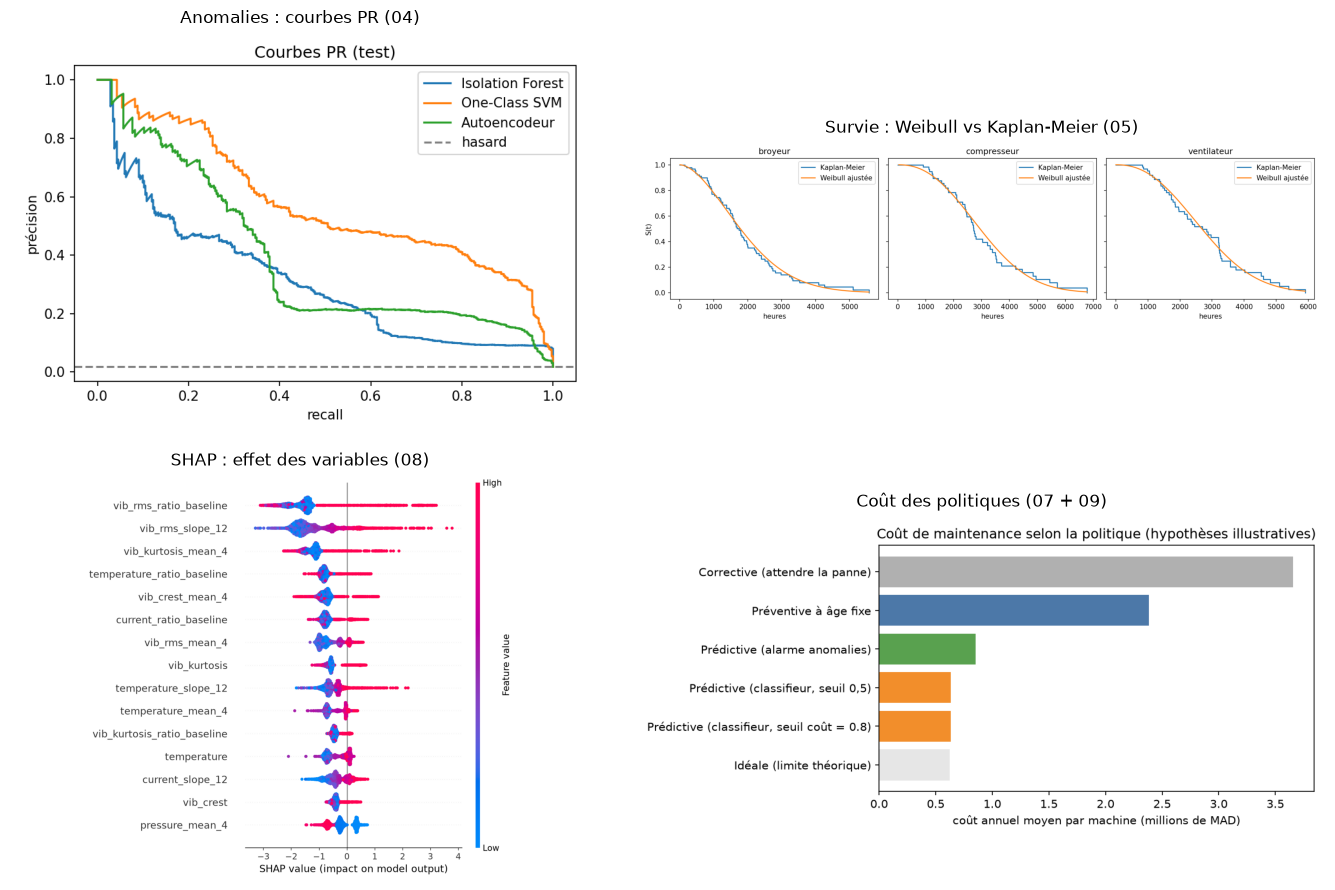

In [11]:
cles = [("anomalies_pr_curves.png", "Anomalies : courbes PR (04)"),
        ("survie_weibull_vs_km.png", "Survie : Weibull vs Kaplan-Meier (05)"),
        ("shap_summary.png", "SHAP : effet des variables (08)"),
        ("cout_politiques_classifieur.png", "Coût des politiques (07 + 09)")]
cles = [(f, t) for f, t in cles if (F / f).exists()]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (f, t) in zip(axes.ravel(), cles):
    ax.imshow(mpimg.imread(F / f)); ax.set_title(t); ax.axis("off")
for ax in axes.ravel()[len(cles):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(F / "comparaison_figures_cles.png", dpi=120); plt.show()

## 9. Tableau de synthèse

Une ligne par approche : a-t-elle besoin d'étiquettes, quelle est sa PR-AUC sur « panne dans 48 h », et combien coûte la politique qui en découle ?

In [12]:
def ligne_cout(prefixe):
    r = cout[cout.index.str.startswith(prefixe)].iloc[-1]       # dernière ligne qui correspond (seuil choisi par le coût)
    return r["MAD/h"], r["économie vs corrective"]

xgb_pr = class_synth.loc["XGBoost", "PR-AUC (test)"]
svm_pr = anomalies.loc["One-Class SVM", "PR-AUC"]
synth = pd.DataFrame([
    ["Corrective (attendre la panne)",     "—",       "—",    *ligne_cout("Corrective")],
    ["Survie : remplacement à âge fixe",   "oui (durées de vie)", "—", *ligne_cout("Préventive")],
    ["Anomalies (One-Class SVM)",          "non",     svm_pr, *ligne_cout("Prédictive (alarme anomalies")],
    ["Classifieur (XGBoost, seuil coût)",  "oui (« panne dans 48 h »)", xgb_pr, *ligne_cout("Prédictive (classifieur, seuil coût")],
    ["Idéale (limite théorique)",          "—",       "—",    *ligne_cout("Idéale")],
], columns=["Approche", "Étiquettes nécessaires", "PR-AUC (panne < 48 h)", "MAD/h", "économie vs corrective"]).set_index("Approche")
synth.to_csv(T / "comparaison_approches.csv")
synth.round(3)

,Étiquettes nécessaires,PR-AUC (panne < 48 h),MAD/h,économie vs corrective
Approche,,,,
Corrective (attendre la panne),—,—,457.100,0%
Survie : remplacement à âge fixe,oui (durées de vie),—,297.865,35%
Anomalies (One-Class SVM),non,0.576,106.280,77%
"Classifieur (XGBoost, seuil coût)",oui (« panne dans 48 h »),0.892,79.154,83%
Idéale (limite théorique),—,—,77.890,83%


## 10. Synthèse (générée à partir des résultats ci-dessus)

In [13]:
corr = cout.loc[cout.index.str.startswith("Corrective"), "MAD/h"].iloc[0]
def mad(prefixe): return cout.loc[cout.index.str.startswith(prefixe), "MAD/h"].iloc[-1]
ideale = mad("Idéale")
print(f"• Détection de « panne dans 48 h » : XGBoost PR-AUC {xgb_pr:.2f}, One-Class SVM PR-AUC {svm_pr:.2f} (hasard ≈ 0,02).")
print(f"• Coût : corrective {corr:.0f} MAD/h ; âge fixe {mad('Préventive'):.0f} ; anomalies {mad('Prédictive (alarme anomalies'):.0f} ; "
      f"classifieur {mad('Prédictive (classifieur, seuil coût'):.0f} ; limite idéale {ideale:.0f}.")
print(f"• Le meilleur compromis est la politique la moins chère hors idéale : "
      f"{cout.drop(cout.index[cout.index.str.startswith('Idéale')])['MAD/h'].idxmin()}.")
print(f"• Capteur le plus important pour le classifieur : {part_capteur.index[0]} ({part_capteur.iloc[0]:.0f} % de l'importance SHAP) ; "
      f"type de feature dominant : {part_type.index[0]} ({part_type.iloc[0]:.0f} %).")

• Détection de « panne dans 48 h » : XGBoost PR-AUC 0.89, One-Class SVM PR-AUC 0.58 (hasard ≈ 0,02).
• Coût : corrective 457 MAD/h ; âge fixe 298 ; anomalies 106 ; classifieur 79 ; limite idéale 78.
• Le meilleur compromis est la politique la moins chère hors idéale : Prédictive (classifieur, seuil coût = 0.8).
• Capteur le plus important pour le classifieur : vib_rms (30 % de l'importance SHAP) ; type de feature dominant : ratio à la baseline (30 %).


### Quand utiliser quoi ?

| Situation | Approche adaptée |
|---|---|
| On a un **historique de pannes étiquetées** | **Classifieur** : la plus précise, donne une probabilité et se règle par le coût |
| **Peu ou pas d'étiquettes** (machines neuves, pannes rares) | **Anomalies** : n'a besoin que de données saines |
| On veut **planifier à l'avance** (stock de pièces, arrêts programmés) | **Survie** : âge optimal de remplacement et durée de vie attendue |
| Pas de données exploitables | Corrective (c'est le point de comparaison le plus coûteux) |

Les approches sont **complémentaires** : la survie planifie, les anomalies surveillent sans étiquettes, le classifieur déclenche l'intervention quand les étiquettes existent.

### Limites

- Données **synthétiques** : la dégradation est simulée (lisse), donc les scores sont **très élevés** (PR-AUC 0,8-0,9 contre 0,018 au hasard). Sur de vraies machines, on s'attend à des résultats nettement plus faibles.
- Coûts **illustratifs** : seul le **rapport** coût d'une panne / coût d'une intervention compte, d'où l'analyse de sensibilité.
- Peu de machines de test (15) et de calibration (9) : les écarts faibles entre modèles proches ne sont **pas significatifs**.
- Le classifieur est supervisé et le simulateur a servi à créer les étiquettes : l'avantage sur les anomalies est probablement **surestimé** par rapport à la réalité.